<a href="https://colab.research.google.com/github/carlocamilloni/Structural-Bioinformatics/blob/main/Notebooks/t08_design.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PROTEIN DESIGN

Until a few years ago a new protein was found, not made: you looked for it in a genome, or you changed a few
residues of one that already existed. Today we can ask for a protein that does not exist in nature and that
does what we want: bind a target, hold a metal, assemble into a ring. The programs that do this are the same
ones we used to *predict* structures (T02), turned around: a network that has learned the relation between
sequence and structure can be run backwards, from the structure you want to a sequence that folds into it.

This practical is about that. You will run the complete pipeline once, on a simple example, and learn how to
tell a design that works from one that does not: this is the part that matters, and the part that the pictures
in the papers do not show. In the report your group will design something real (a nanobody, a binder, or a
protein built around a catalytic site) and will have to defend it with numbers.

## The design loop

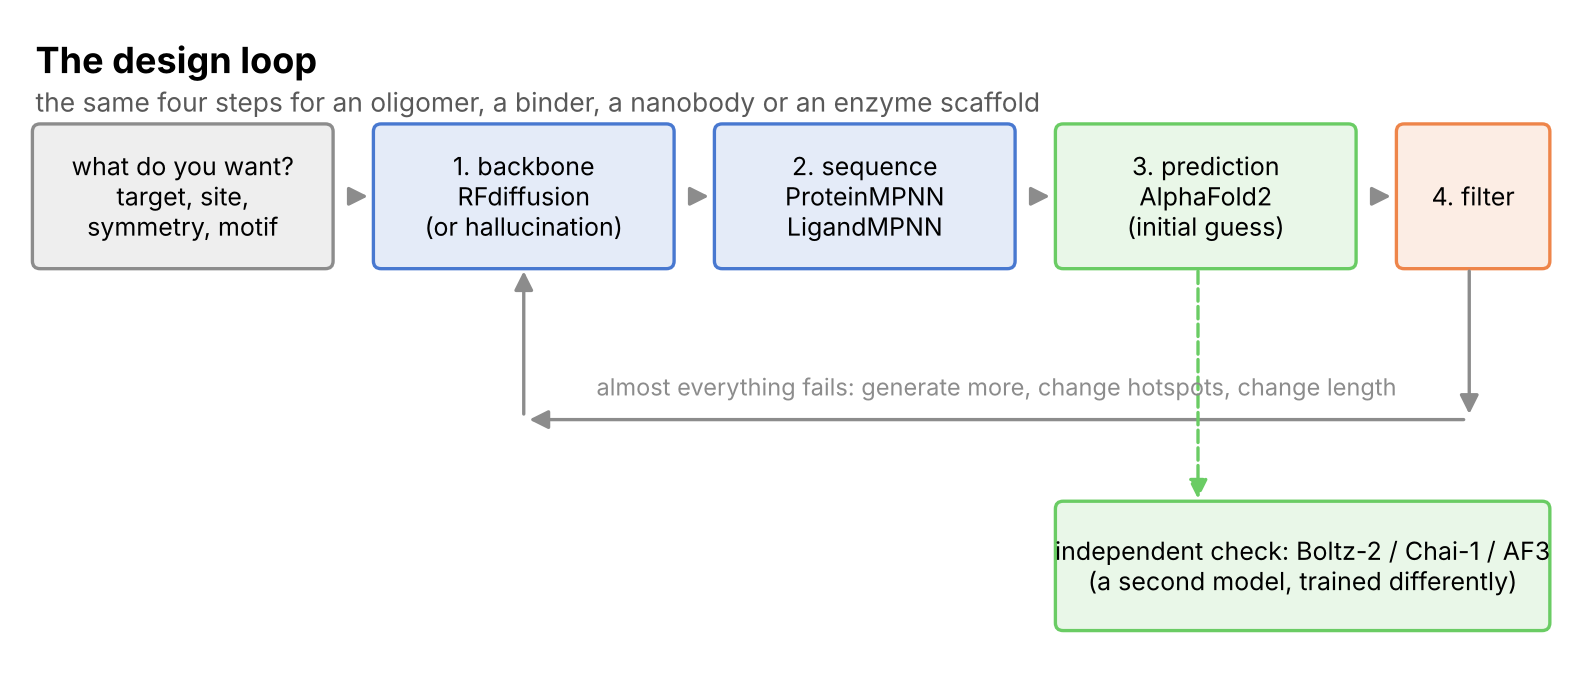

**1. The backbone.** *RFdiffusion* starts from a cloud of random atoms and removes noise step by step until a
protein-like backbone appears, like the image generators that draw a picture from noise. You do not control it
directly: you give it *constraints* (how long, how many copies, which site of which target to bind, which
residues to keep fixed) and it generates backbones that satisfy them. There is no sequence yet, only the chain
of C-alpha, N, C and O atoms.

**2. The sequence.** *ProteinMPNN* reads a backbone and writes a sequence that should fold into it (the
"inverse folding" problem). It is fast, so you ask for several sequences per backbone and keep the best.
*LigandMPNN* does the same but also sees the ligands, the metals and the nucleic acids around the protein,
which changes the residues it chooses next to them.

**3. The prediction.** Now you forget how the design was made and simply predict the structure of the sequence
with *AlphaFold2*, as if it were a protein found in a genome. If the prediction comes back on top of the
backbone you designed, the sequence encodes that structure; if it comes back as something else (or as
spaghetti), the design failed. This is called a **self-consistency** test.

**4. The filter.** The result is a table of numbers, not a protein: confidence of the prediction (pLDDT), error
expected on the relative position of the two chains (pAE at the interface), distance between design and
prediction (RMSD). You set thresholds, you count how many designs survive, and that fraction, the **in silico
success rate**, is the real result of a design campaign. For a binder it is often a few per cent, which is why
nobody designs one protein: you design hundreds and throw away almost all of them.

Steps 3 and 4 have a weakness worth remembering: ProteinMPNN and AlphaFold2 were trained on the same protein
universe and make correlated mistakes, so AlphaFold2 is a generous judge of what ProteinMPNN writes. The usual
defence is to ask a **second, independently trained model** (Boltz-2, Chai-1, AlphaFold3) for an opinion. We
will do that here, and you will see that the two do not always agree.

## The toolbox in 2026

The field moves fast; the table shows what is used today and what we will run. Everything is free and open.

| step | what we use | what else exists |
|:--|:--|:--|
| backbone | **RFdiffusion** (2023), diffusion with constraints | **RFdiffusion2** (2025), scaffolds an active site atom by atom, without telling it the order of the residues; Genie2, Proteina |
| backbone, other idea | **AfDesign** (hallucination): optimise a sequence until AlphaFold2 itself predicts the complex you want | **BindCraft** (2025), the industrial version of the same idea, with the best experimental success rate published for binders; **BoltzDesign1** (2025), the same through a co-folding model, so it can target small molecules, DNA or metals |
| antibodies | **RFantibody** (2025): RFdiffusion retrained on antibodies, designs the CDR loops on a real framework | Germinal (2025); IgDesign |
| sequence | **ProteinMPNN**, **solubleMPNN**, **LigandMPNN** | ESM3 and other protein language models |
| check | **AlphaFold2** with *initial guess*, **Boltz-2** | Chai-1, AlphaFold3, Protenix |
| novelty | **Foldseek** against the PDB and the AlphaFold database | |

What changed since the first version of this practical: antibodies became designable, sequence design learned
about ligands and metals, and above all the way designs are *judged* became part of the method.

One number to keep in mind. These pipelines produce thousands of designs that look perfect on the screen;
when they are expressed in the laboratory, a few per cent bind their target, and the fraction depends enormously
on the target. A design that passes every filter is a hypothesis to be tested, not a result.

# Setup

Run these cells at the beginning of every session (the installation takes about 10-15 minutes and must be
repeated every time Colab gives you a new machine). The whole training then takes roughly half an hour of
computing: plan for it, and do not start it ten minutes before the end of a session.

The installation builds **two** environments: the notebook itself (the Python of Colab, where ProteinMPNN,
AlphaFold2 and all the analysis run) and a small separate environment with an older Python, where RFdiffusion
runs as an external program, because it needs libraries that do not exist for the Python of Colab. Combining
tools that cannot live in the same environment is part of the daily work in this field.

If the cell ends with an error, **run it again**: the weights and the packages already installed are not
downloaded twice, so a second run only does what is missing. The cell prints what it managed to install, so
if it keeps failing you can see where.

Software rots, and this practical is a good example: the server that distributed the `dgl` library stopped
answering in November 2026, which breaks the official installation of RFdiffusion (and of every pipeline that
depends on it). We take the same library from another distribution channel. Expect this kind of archaeology
whenever you use research code; it is the reason a notebook that worked last year may not work today.

In [ ]:
# a GPU is needed for every design tool used here: Runtime -> Change runtime type -> T4 GPU
import subprocess
out = subprocess.run('nvidia-smi --query-gpu=name,memory.total --format=csv,noheader',
                     shell=True, capture_output=True, text=True).stdout.strip()
print('GPU:', out if out else 'NONE -- go to Runtime -> Change runtime type and choose a GPU')

In [ ]:
import os
WORK = '/content' if os.path.isdir('/content') else os.getcwd()   # where the weights were downloaded
os.chdir(WORK)
local_path = os.path.join(WORK, 'T08')                            # where our files go
os.makedirs(local_path, exist_ok=True)
DRIVE_PATH = None                                                 # in the report this points to the group folder
print('working in', local_path)

In [ ]:
%%time
# RFdiffusion (backbones) + ColabDesign (ProteinMPNN and AlphaFold2). 10-15 minutes, once per session.
# The weights are about 5 GB and are downloaded on the virtual machine, not on your Drive.
#
# Two complications, both typical of research software:
#  * RFdiffusion needs the library dgl, which is not published for the Python of Colab, so we build next to
#    the notebook a small environment with an older Python (with uv, a fast installer) and run RFdiffusion
#    inside it as an external program. Everything else (ProteinMPNN, AlphaFold2, Boltz-2, the analysis) runs
#    in the notebook itself.
#  * the server that distributed the dgl packages (data.dgl.ai) has been unreachable since November 2026,
#    so we take the same build from the conda channel of the dgl team, which still works.
import os, re, sys, glob, time, shutil, subprocess

RFD_ENV = os.path.join(WORK, 'rfd-env')                    # the environment of RFdiffusion
RFD_PYTHON = os.path.join(RFD_ENV, 'bin', 'python')
RFD_REPO = os.path.join(WORK, 'RFdiffusion')
AF2_PARAMS = os.path.join(WORK, 'params')                  # where ColabDesign looks for AlphaFold2

def sh(cmd, tries=1, quiet=False):
    # run a shell command; on failure show the end of its output (os.system hides it)
    for t in range(tries):
        p = subprocess.run(cmd, shell=True, capture_output=True, text=True)
        if p.returncode == 0:
            return True
        if t + 1 < tries:
            time.sleep(5)
    if not quiet:
        print('FAILED:', cmd)
        print((p.stdout + p.stderr).strip()[-1200:])
    return False

def imports(modules, python=None):
    # True if those modules can be imported by that interpreter
    return subprocess.run([python or sys.executable, '-c', 'import ' + ', '.join(modules)],
                          capture_output=True).returncode == 0

# --- code ------------------------------------------------------------------------------------------------
if not shutil.which('aria2c'):
    sh('apt-get -qq install aria2')
if not os.path.isfile(os.path.join(RFD_REPO, 'run_inference.py')):   # also repairs an interrupted clone
    shutil.rmtree(RFD_REPO, ignore_errors=True)
    sh(f'cd {WORK} && git clone -q https://github.com/sokrypton/RFdiffusion.git', tries=2)
    if not os.path.isfile(os.path.join(RFD_REPO, 'run_inference.py')):
        raise RuntimeError('could not clone RFdiffusion: check the network and run the cell again')
if not imports(['colabdesign']):
    sh('pip -q install git+https://github.com/sokrypton/ColabDesign.git', tries=2)
    sh('ln -sf /usr/local/lib/python3.*/dist-packages/colabdesign colabdesign')
if not imports(['py3Dmol']):
    sh('pip install -q py3Dmol')

# --- weights (each file is downloaded only if missing: re-running this cell resumes, it does not restart) --
# RFdiffusion looks for its checkpoints in RFdiffusion/models: Base_ckpt for a monomer, an oligomer or a
# motif, Complex_base_ckpt as soon as hotspots are given (a binder). The noise schedules are computed by
# RFdiffusion itself the first time (a couple of minutes) and cached in RFdiffusion/schedules.
os.makedirs(f'{RFD_REPO}/models', exist_ok=True)
IPD = 'http://files.ipd.uw.edu/pub/RFdiffusion'
for ckpt, name in [('6f5902ac237024bdd0c176cb93063dc4', 'Base_ckpt.pt'),
                   ('e29311f6f1bf1af907f9ef9f44b8328b', 'Complex_base_ckpt.pt')]:
    if not os.path.isfile(f'{RFD_REPO}/models/{name}'):
        sh(f'aria2c -q -x 16 {IPD}/{ckpt}/{name} -d {RFD_REPO}/models', tries=2)
# AlphaFold2 (ColabDesign) looks for params/params_model_*.npz in the folder we work from
os.makedirs(AF2_PARAMS, exist_ok=True)
if not glob.glob(os.path.join(AF2_PARAMS, 'params_model_*.npz')):
    sh(f'cd {WORK} && aria2c -q -x 16 '
       f'https://storage.googleapis.com/alphafold/alphafold_params_2022-12-06.tar', tries=2)
    sh(f'tar -xf {WORK}/alphafold_params_2022-12-06.tar -C {AF2_PARAMS}')

# --- the environment of RFdiffusion ------------------------------------------------------------------------
DGL_CONDA = ('https://conda.anaconda.org/dglteam/label/th24_cu124/linux-64/'
             'dgl-2.4.0.th24.cu124-py{tag}_0.tar.bz2')          # dgl 2.4, torch 2.4, CUDA 12.4
DGL_WHEELS = 'https://data.dgl.ai/wheels/torch-2.4/cu124/repo.html'   # the old way, kept in case it returns

def install_dgl(python_version):
    # the conda package contains lib/pythonX.Y/site-packages/dgl, exactly where the environment wants it
    url = DGL_CONDA.format(tag=python_version.replace('.', ''))
    print('  dgl from the conda channel (about 300 MB)')
    if sh(f'curl -sSL --max-time 900 -o /tmp/dgl.tar.bz2 {url}', tries=3, quiet=True):
        sh(f'tar -xjf /tmp/dgl.tar.bz2 -C "{RFD_ENV}" lib/python{python_version}/site-packages/dgl')
        sh('rm -f /tmp/dgl.tar.bz2')
        # libdgl.so looks for the CUDA libraries in <environment>/lib (that is its RPATH); they are the ones
        # that came with torch, inside site-packages/nvidia, so we point to them from there
        for so in (glob.glob(f'{RFD_ENV}/lib/python*/site-packages/nvidia/*/lib/lib*.so*')
                   + glob.glob(f'{RFD_ENV}/lib/python*/site-packages/torch/lib/lib*.so.*')):
            m = re.match(r'(lib[^-]+)-[0-9a-f]{6,}(\.so.*)$', os.path.basename(so))
            link = os.path.join(RFD_ENV, 'lib', m.group(1) + m.group(2) if m else os.path.basename(so))
            if not os.path.exists(link):
                os.symlink(so, link)
    if not imports(['dgl'], RFD_PYTHON):                        # fallback: the old wheel server
        print('  the conda package did not work, trying the old wheel server')
        sh(f'{UV} pip install -q --python "{RFD_PYTHON}" --no-deps dgl -f {DGL_WHEELS}', tries=2)
    return imports(['dgl'], RFD_PYTHON)

def check_rfd_env(verbose=True):
    p = subprocess.run([RFD_PYTHON, '-c',
                        'import torch, dgl, e3nn, hydra, se3_transformer; '
                        'print("torch", torch.__version__, "| dgl", dgl.__version__, '
                        '"| GPU", torch.cuda.is_available())'], capture_output=True, text=True)
    if verbose:
        print('  ' + (p.stdout.strip() or p.stderr.strip()[-700:]))
    return p.returncode == 0

def build_rfd_env(python_version):
    print(f'building the RFdiffusion environment with Python {python_version} (a few minutes)...')
    shutil.rmtree(RFD_ENV, ignore_errors=True)
    sh(f'{UV} venv -q --python {python_version} "{RFD_ENV}"', tries=2)
    add = f'{UV} pip install -q --python "{RFD_PYTHON}"'
    sh(f'{add} torch==2.4.1 --index-url https://download.pytorch.org/whl/cu124', tries=2)
    sh(f'{add} "numpy<2" scipy sympy networkx pandas psutil requests tqdm pydantic packaging setuptools '
       f'omegaconf hydra-core icecream pynvml decorator pyrsistent', tries=2)
    install_dgl(python_version)
    sh(f'{add} --no-deps e3nn==0.5.5 opt_einsum opt_einsum_fx', tries=2)
    sh(f'{add} --no-deps "git+https://github.com/NVIDIA/dllogger#egg=dllogger"', tries=2)
    sh(f'{add} --no-deps {RFD_REPO}/env/SE3Transformer', tries=2)
    return check_rfd_env()

if not shutil.which('uv'):
    sh('pip install -q uv')
UV = shutil.which('uv') or 'uv'                 # the installer that builds the environments
if not (os.path.isfile(RFD_PYTHON) and check_rfd_env(verbose=False)):
    for version in ['3.12', '3.11']:
        if build_rfd_env(version):
            break

RUN_INFERENCE = os.path.join(RFD_REPO, 'run_inference.py')
print('RFdiffusion     :', len(glob.glob(f'{RFD_REPO}/models/*_ckpt.pt')), 'checkpoints')
print('AlphaFold2      :', len(glob.glob(os.path.join(AF2_PARAMS, 'params_model_*.npz'))),
      'weight files')
print('environment     :', end=' ')
if not check_rfd_env():
    raise RuntimeError('the environment of RFdiffusion is not working (see the messages above)')

The helper functions used everywhere below. They are short: read them, you will need to know what they
compute when you discuss your results.

Two warnings about **units**. ColabDesign reports `plddt` between 0 and 1 and the errors `pae`/`i_pae`
divided by 31; the literature uses pLDDT between 0 and 100 and pAE in Ångström. `read_designs()` converts
everything to the usual units, so the thresholds below are the ones you find in papers.

In [ ]:
import os, re, json, glob, time, pickle, shutil, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PAE_SCALE = 31.0          # ColabDesign divides pae and i_pae by 31

# --- results of a design run -------------------------------------------------------

def read_designs(loc):
    """the table written by designability_test.py, converted to the usual units"""
    df = pd.read_csv(os.path.join(loc, 'mpnn_results.csv'), index_col=0)
    if df['plddt'].max() <= 1.5:                  # ColabDesign writes pLDDT between 0 and 1
        df['plddt'] = 100 * df['plddt']
    for c in ['pae', 'i_pae']:                    # these are already in Å (the script multiplies them)
        if c in df.columns and df[c].max() <= 1.0:
            df[c] = PAE_SCALE * df[c]
    df['pdb'] = [os.path.join(loc, 'all_pdb', f'design{int(d)}_n{int(n)}.pdb')
                 for d, n in zip(df['design'], df['n'])]
    return df

# the filters used in the literature for this kind of design
FILTERS = {'monomer': dict(plddt=('>', 80), rmsd=('<', 2.0)),
           'oligomer': dict(plddt=('>', 80), rmsd=('<', 2.0), i_pae=('<', 10)),
           'binder':   dict(plddt=('>', 80), rmsd=('<', 2.0), i_pae=('<', 10), i_ptm=('>', 0.5))}

def apply_filters(df, kind='binder', **overrides):
    """add a column pass_X for every filter and a column 'accepted' for designs that pass all of them"""
    thr = dict(FILTERS[kind]); thr.update({k: v for k, v in overrides.items()})
    df = df.copy()
    ok = np.ones(len(df), dtype=bool)
    for name, (op, value) in thr.items():
        if name not in df.columns:
            continue
        col = df[name] > value if op == '>' else df[name] < value
        df['pass_' + name] = col
        ok &= col.values
    df['accepted'] = ok
    return df, thr

def funnel(df, thr, title='', name=None):
    """how many designs survive each filter, applied one after the other (the design funnel)"""
    labels, counts = ['generated'], [len(df)]
    keep = np.ones(len(df), dtype=bool)
    for n, (op, v) in thr.items():
        if n not in df.columns:
            continue
        keep = keep & ((df[n] > v) if op == '>' else (df[n] < v)).values
        labels.append(f'{n} {op} {v}')
        counts.append(int(keep.sum()))
    fig, ax = plt.subplots(figsize=(1.3 * len(labels) + 1, 3.2))
    ax.bar(labels, counts, color=['0.7'] + ['#4878d0'] * (len(labels) - 1))
    for i, c in enumerate(counts):
        ax.text(i, c, str(c), ha='center', va='bottom')
    ax.set_ylabel('designs'); ax.set_title(title)
    ax.set_ylim(0, max(counts) * 1.2)
    plt.xticks(rotation=20, ha='right'); plt.tight_layout()
    print(f'success rate: {counts[-1]}/{counts[0]} = {100*counts[-1]/max(counts[0],1):.0f}%')
    if name:
        save_figure(fig, name)
    return fig

def oligomer_contigs(pdb):
    """the contigs of a symmetric oligomer for the designability test: one segment per chain.
    The test divides the residues it reads by `copies`, so it must be given every chain of the design."""
    ca = read_pdb(pdb)
    ca = ca[(ca.name == 'CA') & (~ca.hetero)]
    order = list(dict.fromkeys(ca.chain))
    return ':'.join(f'{int((ca.chain == c).sum())}-{int((ca.chain == c).sum())}' for c in order)

def chains_to_AB(pdb):
    """put the target (the longest chain) in chain A and the binder in chain B: the designability test
    assigns the chain letters by position, so a complex must really be named A and B."""
    a = read_pdb(pdb)
    target, binder = guess_chains(a)
    if (target, binder) == ('A', 'B') or binder is None:
        return False
    m = {target: 'A', binder: 'B'}
    a = a.copy()
    a['line'] = [l[:21] + m.get(l[21], l[21]) + l[22:] for l in a.line]
    write_pdb(a, pdb)
    return True

def binder_contigs(pdb):
    """the contigs of a two-chain design, as the designability test wants them: the first chain (the target)
    is kept, the second (the binder) is redesigned. Lengths are taken from the design itself."""
    ca = read_pdb(pdb)
    ca = ca[(ca.name == 'CA') & (~ca.hetero)]
    order = list(dict.fromkeys(ca.chain))                     # chains in the order of the file
    n = {c: int((ca.chain == c).sum()) for c in order}
    target, binder = order[0], order[1]
    return f'A1-{n[target]}:{n[binder]}-{n[binder]}'

def motif_contigs(pdb):
    """the contigs of a scaffolded motif, from the .trb that RFdiffusion writes next to the design:
    the motif residues are kept, the rest is redesigned (the lengths are those actually generated)."""
    trb = pickle.load(open(pdb.replace('.pdb', '.trb'), 'rb'))
    motif = sorted(r for _, r in trb['con_hal_pdb_idx'])
    ca = read_pdb(pdb)
    total = int(((ca.name == 'CA') & (~ca.hetero)).sum())
    parts, i = [], 1
    for r in motif:
        if r < i:
            continue
        end = r
        while end + 1 in motif:
            end += 1
        if r > i:
            parts.append(f'{r-i}-{r-i}')
        parts.append(f'A{r}-{end}')
        i = end + 1
    if i <= total:
        parts.append(f'{total-i+1}-{total-i+1}')
    return '/'.join(parts)

# --- reading and comparing structures (no external dependency) ----------------------

AA3 = {'ALA':'A','ARG':'R','ASN':'N','ASP':'D','CYS':'C','GLN':'Q','GLU':'E','GLY':'G','HIS':'H',
       'ILE':'I','LEU':'L','LYS':'K','MET':'M','PHE':'F','PRO':'P','SER':'S','THR':'T','TRP':'W',
       'TYR':'Y','VAL':'V','MSE':'M'}

def read_pdb(filename):
    """atoms of a pdb file as a DataFrame (name, resname, chain, resi, x, y, z, element, hetero)"""
    rows = []
    for l in open(filename):
        if l.startswith(('ATOM', 'HETATM')):
            rows.append(dict(name=l[12:16].strip(), resname=l[17:20].strip(), chain=l[21],
                             resi=int(l[22:26]), x=float(l[30:38]), y=float(l[38:46]), z=float(l[46:54]),
                             element=l[76:78].strip() or l[12:16].strip()[0], hetero=l.startswith('HETATM'),
                             line=l.rstrip('\n')))
    return pd.DataFrame(rows)

def sequence_of(atoms, chain=None):
    sel = atoms[(atoms.name == 'CA') & (~atoms.hetero)]
    if chain:
        sel = sel[sel.chain == chain]
    return ''.join(AA3.get(r, 'X') for r in sel.resname)

def write_pdb(atoms, filename):
    with open(filename, 'w') as f:
        for l in atoms.line:
            f.write(l + '\n')
        f.write('END\n')

def kabsch(P, Q):
    """rotation and translation that superpose P on Q, and the rmsd after superposition"""
    Pc, Qc = P - P.mean(0), Q - Q.mean(0)
    V, S, Wt = np.linalg.svd(Pc.T @ Qc)
    d = np.sign(np.linalg.det(V @ Wt))
    R = V @ np.diag([1, 1, d]) @ Wt
    rot = Pc @ R
    return R, Q.mean(0) - P.mean(0) @ R, float(np.sqrt(((rot - Qc) ** 2).sum() / len(P)))

def ca_rmsd(pdb1, pdb2, chain1=None, chain2=None, resi1=None, resi2=None):
    """C-alpha rmsd after superposition; resi1/resi2 select the residues to use (e.g. a motif)"""
    def ca(f, ch, resi):
        a = read_pdb(f) if isinstance(f, str) else f
        a = a[(a.name == 'CA') & (~a.hetero)]
        if ch:
            a = a[a.chain == ch]
        if resi is not None:
            a = a[a.resi.isin(resi)]
        return a[['x', 'y', 'z']].values
    P, Q = ca(pdb1, chain1, resi1), ca(pdb2, chain2, resi2)
    n = min(len(P), len(Q))
    return kabsch(P[:n], Q[:n])[2]

def superpose_onto(mobile_pdb, ref_pdb, mobile_resi, ref_resi, out_pdb, mobile_chain=None, ref_chain=None,
                   atom_names=('N', 'CA', 'C', 'O')):
    """superpose a structure on another using the selected residues (paired in the order given),
    and write the moved structure. The whole backbone is used, not only the C-alpha: two residues give
    8 atoms, enough to fix the orientation, while two C-alpha alone would not."""
    m, r = read_pdb(mobile_pdb), read_pdb(ref_pdb)
    def ca(a, ch, resi):
        s = a[a.name.isin(atom_names) & (~a.hetero) & (a.resi.isin(list(resi)))]
        if ch:
            s = s[s.chain == ch]
        order = {n: i for i, n in enumerate(atom_names)}
        s = s.assign(_o=[order[n] for n in s.name]).sort_values(['resi', '_o'])
        return s[['x', 'y', 'z']].values
    P, Q = ca(m, mobile_chain, mobile_resi), ca(r, ref_chain, ref_resi)
    if len(P) != len(Q) or len(P) < 3:
        raise ValueError(
            f'cannot superpose {os.path.basename(mobile_pdb)} on {os.path.basename(ref_pdb)}: '
            f'{len(P)} and {len(Q)} atoms selected. Chains present: '
            f'{chain_sizes(m)} and {chain_sizes(r)} - pass mobile_chain/ref_chain to choose one.')
    R, t, rms = kabsch(P, Q)
    xyz = m[['x', 'y', 'z']].values @ R + t
    lines = []
    for l, (x, y, z) in zip(m.line, xyz):
        lines.append(f'{l[:30]}{x:8.3f}{y:8.3f}{z:8.3f}{l[54:]}')
    with open(out_pdb, 'w') as f:
        f.write('\n'.join(lines) + '\nEND\n')
    print(f'{os.path.basename(out_pdb)}: motif rmsd {rms:.2f} A')
    return rms

def chain_sizes(pdb):
    """number of residues per chain"""
    a = read_pdb(pdb) if isinstance(pdb, str) else pdb
    a = a[(a.name == 'CA') & (~a.hetero)]
    return a.groupby('chain').size().sort_values(ascending=False).to_dict()

def guess_chains(pdb):
    """(target, binder): the longest chain is the target, the shortest the binder/nanobody"""
    s = chain_sizes(pdb)
    if len(s) < 2:
        return (list(s)[0], None) if s else (None, None)
    ch = list(s)
    return ch[0], ch[-1]

def contacts(pdb, chain_a, chain_b, cutoff=5.0):
    """residues of chain_a with at least one atom within cutoff of chain_b (the interface), ligands excluded"""
    a = read_pdb(pdb) if isinstance(pdb, str) else pdb
    a = a[~a.hetero]
    A, B = a[a.chain == chain_a], a[a.chain == chain_b]
    if len(A) == 0 or len(B) == 0:
        return []
    d = np.linalg.norm(A[['x','y','z']].values[:, None, :] - B[['x','y','z']].values[None, :, :], axis=-1)
    close = (d < cutoff).any(1)
    return sorted(int(r) for r in set(A.resi.values[close]))

# --- viewing -----------------------------------------------------------------------

def show(*pdbs, colors=('lightblue', 'salmon', 'palegreen', 'khaki'), sticks=None, spheres=True):
    """show one or more pdb files; sticks = list of (chain, resi) to show as sticks"""
    import py3Dmol
    view = py3Dmol.view(width=700, height=500)
    for i, p in enumerate(pdbs):
        view.addModel(open(p).read(), 'pdb')
        view.setStyle({'model': i}, {'cartoon': {'color': colors[i % len(colors)]}})
        if spheres:
            view.addStyle({'model': i, 'hetflag': True}, {'sphere': {'scale': 0.4}})
    for ch, resi in (sticks or []):
        view.addStyle({'chain': ch, 'resi': str(resi)}, {'stick': {'colorscheme': 'yellowCarbon'}})
    view.zoomTo()
    return view.show()

# --- an independent opinion: Boltz-2 ------------------------------------------------

def boltz_yaml(path, chains, ligand=None, msa='empty', affinity_of=None):
    """write a Boltz input: chains = {'A': sequence, ...}, ligand = ('B', 'ZN') or ('B', 'smiles:CCO')"""
    lines = ['version: 1', 'sequences:']
    for cid, seq in chains.items():
        lines += [f'  - protein:', f'      id: {cid}', f'      sequence: {seq}', f'      msa: {msa}']
    if ligand:
        cid, code = ligand
        key, val = ('smiles', code[7:]) if code.startswith('smiles:') else ('ccd', code)
        lines += [f'  - ligand:', f'      id: {cid}', f"      {key}: {val}"]
    if affinity_of:
        lines += ['properties:', '  - affinity:', f'      binder: {affinity_of}']
    open(path, 'w').write('\n'.join(lines) + '\n')
    return path

BOLTZ_ENV = 'boltz-env'          # Boltz-2 has its own environment (see install_boltz below)

def install_boltz(rerun=False):
    """Boltz-2 in an environment of its own: it pins numpy, scipy, dm-tree and torch to versions that have
    no wheels for the Python of Colab (dm-tree would have to be compiled). As for RFdiffusion, we install it
    next to the notebook with uv and use it as an external program. A few minutes and about 3 GB."""
    env = os.path.join(WORK, BOLTZ_ENV)
    boltz = os.path.join(env, 'bin', 'boltz')
    if os.path.isfile(boltz) and not rerun:
        return boltz
    if not shutil.which('uv'):
        subprocess.run('pip install -q uv', shell=True)
    print('building the Boltz-2 environment (a few minutes)...')
    subprocess.run(f'uv venv -q --python 3.12 "{env}"', shell=True)
    p = subprocess.run(f'uv pip install -q --python "{env}/bin/python" boltz',
                       shell=True, capture_output=True, text=True)
    if not os.path.isfile(boltz):
        print((p.stdout + p.stderr).strip()[-1500:])
        raise RuntimeError('could not install Boltz-2')
    print('Boltz-2 is ready')
    return boltz

def run_boltz(yaml_file, out_dir='boltz', samples=1, recycles=3, use_msa_server=False, rerun=False):
    """run Boltz-2 and return the confidence of the first model (and the path of the structure)"""
    name = os.path.basename(yaml_file).replace('.yaml', '')
    conf = os.path.join(out_dir, 'boltz_results_' + name, 'predictions', name, f'confidence_{name}_model_0.json')
    if rerun or not os.path.isfile(conf):
        cmd = (f'{install_boltz()} predict {yaml_file} --out_dir {out_dir} --output_format pdb '
               f'--diffusion_samples {samples} --recycling_steps {recycles} --override')
        if use_msa_server:
            cmd += ' --use_msa_server'
        t0 = time.time()
        r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
        if not os.path.isfile(conf):
            print(r.stdout[-2000:], r.stderr[-2000:])
            raise RuntimeError('boltz failed')
        print(f'{name}: {time.time()-t0:.0f} s')
    c = json.load(open(conf))
    c['pdb'] = conf.replace('confidence_', '').replace('.json', '.pdb')
    save_file_to_drive(conf); save_file_to_drive(c['pdb'])
    return c

# --- saving ------------------------------------------------------------------------

def save_file_to_drive(filename):
    """copy one file to the group folder on Google Drive (only this file: never a whole folder)"""
    if DRIVE_PATH and os.path.isfile(filename):
        relative = os.path.relpath(os.path.abspath(filename), local_path)
        if relative.startswith('..'):            # outside the group folder: not ours to copy
            return
        target = os.path.join(DRIVE_PATH, relative)
        os.makedirs(os.path.dirname(target), exist_ok=True)
        shutil.copy2(filename, target)

def save_figure(fig, name):
    """save a figure for your presentation in the folder figures (also on Google Drive)"""
    os.makedirs(os.path.join(local_path, 'figures'), exist_ok=True)
    f = os.path.join(local_path, 'figures', name + '.png')
    fig.savefig(f, dpi=200, bbox_inches='tight')
    save_file_to_drive(f)
    print('saved figures/' + name + '.png')

def save_json(data, filename):
    os.makedirs(os.path.dirname(filename) or '.', exist_ok=True)
    def plain(o):                      # numpy types are not json
        if isinstance(o, (np.integer,)): return int(o)
        if isinstance(o, (np.floating,)): return float(o)
        if isinstance(o, (np.ndarray,)): return o.tolist()
        return str(o)
    json.dump(data, open(filename, 'w'), indent=1, default=plain)
    save_file_to_drive(filename)

def load_results(pattern, what='results'):
    """read into one table the json files of every member of the group (and say so if there are none)"""
    data = load_json(pattern)
    if not data:
        raise FileNotFoundError(
            f'no {what} found as {os.path.basename(pattern)}. Either nobody in the group has run that '
            f'part yet, or the group folder is not synchronised: run sync_from_drive() and look into '
            f'{os.path.dirname(pattern)}')
    return pd.concat([pd.DataFrame(v) for v in data.values()], ignore_index=True)

def load_json(pattern):
    """read all the json files matching a pattern, also those made by the other members of the group"""
    out = {}
    for f in sorted(glob.glob(pattern)):
        if ' (' in f:            # a duplicate made by Google Drive
            continue
        out[os.path.basename(f).replace('.json', '')] = json.load(open(f))
    return out

# --- the input structures ----------------------------------------------------------

def fetch_pdb(code, chains=None, keep_hetero=(), out=None, renumber=False, rename_chain=None):
    """download a structure from the PDB and keep what we need (chains, ligands, no water)"""
    code = code.lower()
    out = out or os.path.join(local_path, f'{code}.pdb')
    os.makedirs(os.path.dirname(out) or '.', exist_ok=True)
    raw = os.path.join(os.path.dirname(out) or '.', code + '_raw.pdb')
    for attempt in range(2):
        if os.path.isfile(raw) and os.path.getsize(raw) > 1000:
            break
        subprocess.run(f'wget -q -O {raw} https://files.rcsb.org/download/{code.upper()}.pdb', shell=True)
    if not (os.path.isfile(raw) and os.path.getsize(raw) > 1000):
        raise RuntimeError(f'could not download {code.upper()} from the PDB (no network?)')
    seen, n = set(), 0
    with open(out, 'w') as f:
        for l in open(raw):
            if not l.startswith(('ATOM', 'HETATM')):
                continue
            if l[16] not in (' ', 'A'):                      # keep one conformation only
                continue
            ch, resn = l[21], l[17:20].strip()
            if chains and ch not in chains:
                continue
            if l.startswith('HETATM') and resn not in keep_hetero:
                continue
            if (ch, l[22:27]) not in seen:
                seen.add((ch, l[22:27])); n += 1
            if rename_chain:
                l = l[:21] + rename_chain.get(ch, ch) + l[22:]
            f.write(l)
        f.write('END\n')
    print(f'{out}: {n} residues')
    return out

In [ ]:
import colabdesign
COLABDESIGN = os.path.dirname(colabdesign.__file__)
DESIGNABILITY = os.path.join(COLABDESIGN, 'rf', 'designability_test.py')

def run(cmd, log, rerun=False, done=None):
    """run a command from the WORK folder, keep its output in a log file, do not repeat work already done"""
    if not rerun and done and all(os.path.exists(f) for f in done):
        print('already done:', ', '.join(os.path.basename(f) for f in done)); return
    t0 = time.time()
    os.makedirs(os.path.dirname(log) or '.', exist_ok=True)
    with open(log, 'w') as f:
        p = subprocess.run(cmd, shell=True, cwd=WORK, stdout=f, stderr=subprocess.STDOUT)
    if p.returncode or (done and not all(os.path.exists(f) for f in done)):
        print(open(log).read()[-3000:])
        raise RuntimeError(f'the command failed (exit code {p.returncode}), see ' + log)
    print(f'done in {time.time()-t0:.0f} s  (log: {os.path.basename(log)})')

def run_rfdiffusion(name, contigs, pdb=None, num_designs=4, steps=50, symmetry=None, order=1,
                    hotspot=None, partial_T=None, extra='', rerun=False):
    """generate backbones with RFdiffusion; returns the list of pdb files"""
    out = os.path.join(local_path, name, name)
    os.makedirs(os.path.dirname(out), exist_ok=True)
    opts = [f'inference.output_prefix={out}', f'inference.num_designs={num_designs}',
            f'diffuser.T={steps}',
            f"'contigmap.contigs=[{contigs}]'"]
    if pdb:       opts.append(f'inference.input_pdb={pdb}')
    if hotspot:   opts.append(f"'ppi.hotspot_res=[{hotspot}]'")
    if partial_T: opts.append(f'diffuser.partial_T={partial_T}')
    if symmetry:                                     # symmetric oligomers need their own configuration file
        opts = ['--config-name symmetry', f'inference.symmetry={symmetry}',
                'potentials.guiding_potentials=[\\"type:olig_contacts,weight_intra:1,weight_inter:0.1\\"]',
                'potentials.olig_intra_all=True', 'potentials.olig_inter_all=True',
                'potentials.guide_scale=2', 'potentials.guide_decay=quadratic'] + opts
    files = [f'{out}_{i}.pdb' for i in range(num_designs)]
    run(f'DGLBACKEND=pytorch {RFD_PYTHON} {RUN_INFERENCE} ' + ' '.join(opts) + ' ' + extra,
        log=out + '_rfdiffusion.log', rerun=rerun, done=files)
    for f in files:
        save_file_to_drive(f)
    return files

def run_designability(pdbs, name, contigs, copies=1, num_seqs=8, soluble=False, initial_guess=False,
                      multimer=False, recycles=3, temp=0.1, rerun=False):
    """ProteinMPNN + AlphaFold2 on each backbone; returns the table of metrics"""
    loc = os.path.join(local_path, name, 'designability')
    os.makedirs(loc, exist_ok=True)
    tables = []
    for i, pdb in enumerate(sorted(pdbs)):
        sub = os.path.join(loc, os.path.basename(pdb).replace('.pdb', ''))
        opts = (f'--pdb={pdb} --loc={sub} --contigs={contigs} --copies={copies} --num_seqs={num_seqs} '
                f'--num_recycles={recycles} --mpnn_sampling_temp={temp}')
        if soluble:       opts += ' --use_soluble'
        if initial_guess: opts += ' --initial_guess'
        if multimer:      opts += ' --use_multimer'
        run(f'python {DESIGNABILITY} {opts}', log=sub + '.log', rerun=rerun,
            done=[os.path.join(sub, 'mpnn_results.csv')])
        t = read_designs(sub)
        t.insert(0, 'backbone', os.path.basename(pdb).replace('.pdb', ''))
        tables.append(t)
    df = pd.concat(tables, ignore_index=True)
    save_json(df.drop(columns=['pdb']).to_dict(orient='list'), os.path.join(loc, 'all_results.json'))
    return df

# Part 1: a first design, a protein that forms a ring

The example: a **cyclic homo-oligomer**, four copies of the same 70-residue chain arranged with C4 symmetry
(like many natural pores and enzymes). It needs no target structure, it is quick, and it already requires
everything: constraints, symmetry, sequence design and validation.

## The contig language

RFdiffusion takes its constraints in a short language, the **contigs**. Each element is either a number
(*that many new residues, invent them*) or a piece of an existing structure (*keep these residues, with their
geometry*):

| contigs | meaning |
|:--|:--|
| `100-100` | a new chain of exactly 100 residues |
| `80-120` | a new chain of a length chosen at random between 80 and 120 |
| `T18-132/0 60-80` | chain T of the input structure, residues 18 to 132, then a chain break (`/0`), then a new chain of 60 to 80 residues: this is a **binder** |
| `10-30/A94-96/5-20/A119-119/10-30` | invent 10-30 residues, keep residues 94-96 of chain A, invent 5-20, keep residue 119, invent 10-30: this is **motif scaffolding** |
| `280-280` with `inference.symmetry=C4` | 280 residues in total, i.e. four copies of 70, with four-fold symmetry |

Two more options that we will use in the report:

* `ppi.hotspot_res=[T56,T58]` tells the model *which residues of the target you want to be touched*. It does
  not force anything, it biases the generation towards that patch, and it is the main handle you have on where
  the binder lands.
* `diffuser.partial_T=10` starts the diffusion from an existing structure instead of from noise, and only
  partly destroys it: it is how you generate variations of a design you already like.

In [ ]:
# two backbones, C4 symmetry, 4 x 70 = 280 residues. Several minutes on a T4: the cost of the diffusion
# grows with the total length, so a symmetric oligomer is not a small job.
oligomer = run_rfdiffusion('oligomer', contigs='280-280', symmetry='C4', num_designs=2, steps=50)
oligomer

In [ ]:
show(oligomer[0])     # the backbone: no side chains, no sequence yet

## From a backbone to a protein

`designability_test.py` does steps 2 and 3 in one go: ProteinMPNN writes `num_seqs` sequences for the
backbone, AlphaFold2 predicts each of them, and the result is a table with one row per sequence. For a
symmetric oligomer we tell it the length of **one** chain and how many `copies` there are.

The columns:

| column | meaning | good value |
|:--|:--|:--|
| `mpnn` | score of ProteinMPNN for its own sequence (lower = the sequence fits the backbone better) | - |
| `plddt` | confidence of AlphaFold2, per residue, averaged (0-100) | > 80 |
| `ptm` / `i_ptm` | expected accuracy of the whole structure / of the interface between chains (0-1) | > 0.8 / > 0.5 |
| `pae` / `i_pae` | expected error on relative positions, inside a chain / between chains (Å) | < 10 |
| `rmsd` | distance between the AlphaFold2 prediction and the backbone you designed (Å) | < 2 |
| `seq` | the designed sequence | - |

`rmsd` and `i_pae` are the two that matter: the first says *AlphaFold2 agrees that this sequence makes this
shape*, the second *AlphaFold2 is confident about how the chains sit against each other*.

In [ ]:
# the contigs of the designability test are read from the design itself: one segment per chain
contigs = oligomer_contigs(oligomer[0])
copies = len(contigs.split(':'))
print('contigs:', contigs, '| copies:', copies)

# 4 sequences per backbone (AlphaFold2 predicts the whole ring every time, so this is the slow part;
# raise it if you have time left)
results = run_designability(oligomer, 'oligomer', contigs=contigs, copies=copies, num_seqs=4)
display(results[['backbone', 'n', 'mpnn', 'plddt', 'ptm', 'i_ptm', 'pae', 'i_pae', 'rmsd']].round(2))

In [ ]:
# the funnel: how many designs survive the filters, one after the other
filtered, thr = apply_filters(results, 'oligomer')
funnel(filtered, thr, title=f'cyclic oligomer, {copies} copies')
if not filtered.accepted.any():
    print('no design passed every filter: we look at the closest one, but do not trust it')
best = (filtered[filtered.accepted] if filtered.accepted.any() else filtered).sort_values('rmsd').iloc[0]
print('best sequence:', best.seq)

In [ ]:
# the design (grey) and what AlphaFold2 predicts from its sequence alone (blue): do they superpose?
show(best.pdb, oligomer[0], colors=('lightblue', '0.7'))

Look at the table before going on. Typically some sequences fold exactly into the designed backbone
(rmsd < 1 Å, pLDDT > 90) and others do not (rmsd of 10 Å or more): the backbone is the same, so what fails is
the *sequence*, which is why we generate several per backbone and why `mpnn_sampling_temp` (how adventurous
ProteinMPNN is allowed to be) is worth playing with when nothing passes.

If **no** sequence works, the backbone itself is probably bad: generate more of them, or change the length.

# Part 2: a second opinion

AlphaFold2 has just told us that the sequence written by ProteinMPNN folds into the backbone drawn by
RFdiffusion. The three programs come from the same world and have seen the same structures, and it is known
that AlphaFold2 is too optimistic about designed sequences: it is a referee with an interest in the match.

So we ask an **independently trained** model, Boltz-2 (2025, open source, the same family as AlphaFold3). Note
two things in the cell: we give it the sequence only, with `msa: empty`, because a designed protein has no
family and no evolutionary information to align; and it returns its own confidence numbers, which you can
compare with those of AlphaFold2.

*Boltz-2 also gets an environment of its own (it needs different versions of torch, numpy and other
libraries from everything else here), so installing it changes nothing for RFdiffusion or AlphaFold2. The
first cell takes a few minutes; the first prediction also downloads the weights of the model.*

In [ ]:
install_boltz()      # a few minutes the first time, nothing the next times

In [ ]:
# the same oligomer: four copies of the designed sequence, no MSA
# ProteinMPNN returns one sequence for a symmetric oligomer: we give Boltz that sequence `copies` times
yaml = boltz_yaml(os.path.join(local_path, 'oligomer', 'oligomer_best.yaml'),
                  chains={c: best.seq for c in 'ABCDEFGH'[:copies]})
conf = run_boltz(yaml, out_dir=os.path.join(local_path, 'oligomer', 'boltz'))
print({k: round(v, 3) for k, v in conf.items() if isinstance(v, float)})
print(f"\nAlphaFold2 : plddt {best.plddt:.0f}, i_ptm {best.get('i_ptm', float('nan')):.2f}")
print(f"Boltz-2    : plddt {100*conf['complex_plddt']:.0f}, i_ptm {conf['iptm']:.2f}")
show(conf['pdb'], best.pdb, colors=('palegreen', 'lightblue'))

Three outcomes are possible, and all three are informative:

* both models agree and are confident: the design is as good as a computer can say;
* AlphaFold2 is confident and Boltz-2 is not: a frequent case for designed proteins, and a reason to be
  careful. It does not prove the design is wrong, it proves that the agreement in Part 1 was partly circular;
* both are unsure: the design is bad.

In a real campaign this second model is one of the filters, not a curiosity.

# Part 3: is it new?

A design that works may simply be a protein that already exists: the networks learned on the PDB, and nothing
stops them from redrawing a fold they know. **Foldseek** compares a structure with the whole PDB and the
AlphaFold database in seconds.

Run the cell, download `best_design.pdb` from the file browser on the left, and upload it to
[search.foldseek.com](https://search.foldseek.com). Then answer two questions: what is the closest known
structure, and how similar is it (TM-score, E-value)? And is the *sequence* identity to it high or low? A
design that is structurally close to a natural protein but has 20% sequence identity is still a new protein;
one that comes back with 90% identity is a protein you have rediscovered.

In [ ]:
import shutil
shutil.copy(best.pdb, os.path.join(local_path, 'best_design.pdb'))
print('upload', os.path.join(local_path, 'best_design.pdb'), 'to https://search.foldseek.com')
print('sequence:', best.seq)

# Part 4: the recipes you will need

Your group will use one of these. The rest of the pipeline (sequences, prediction, filters, second opinion,
Foldseek) is identical, and the functions above do not change.

| you want | contigs and options | filters |
|:--|:--|:--|
| **an oligomer** (this training) | `280-280`, `inference.symmetry=C4` | `oligomer` |
| **a binder** of 60-80 residues on chain T | `T18-132/0 60-80`, `ppi.hotspot_res=[T56,T58,T113]`, `inference.input_pdb=target.pdb` | `binder` (add `--initial_guess --use_multimer` in the designability test) |
| **a scaffold around a site** | `10-30/A94-96/5-20/A119-119/10-30`, `inference.input_pdb=site.pdb` | `monomer` + the rmsd of the motif |
| **variations of a design** | the same contigs, plus `diffuser.partial_T=10` | as above |

**Careful: the designability test speaks a slightly different dialect.** RFdiffusion takes the contigs you
*ask for* (ranges, chain breaks `/0`); the designability test takes the contigs of the design you *obtained*,
with one segment per chain separated by `:`, every segment written as a range (`90-90`, not `90`), and the
kept parts written with a chain letter (`A1-115`). Two functions build that string for you from the design
itself: `oligomer_contigs(pdb)` (one segment per chain, because the test divides what it reads by the number
of copies), `binder_contigs(pdb)` for a complex, and `motif_contigs(pdb)` for a scaffolded motif (it reads the
`.trb` file that RFdiffusion writes next to every design, because the lengths between the motif residues were
chosen at random inside your ranges). For a complex, `chains_to_AB(pdb)` makes sure the target is chain A and
the binder chain B, which is what the test assumes.

A few practical rules that cost nothing and save hours:

1. **Trim the target.** RFdiffusion and AlphaFold2 cost time in proportion to the total number of residues:
   keep the domain you want to bind, not the whole protein.
2. **Generate in batches.** 10 backbones x 8 sequences is a reasonable unit of work on a T4; keep the metrics
   of everything you generate, including the failures, because the success rate is a result.
3. **Change one thing at a time.** Hotspots, binder length, number of diffusion steps: if you change three at
   once you will not know what worked.
4. **Keep the numbers, not the pictures.** Every design in your report must come with its table row.

# Going further

* **RFdiffusion2** (Nat. Methods 2025) scaffolds an enzyme active site given only the catalytic atoms, without
  telling it which residue comes first in the sequence; it is the natural successor of the motif scaffolding
  you will do in the report, but it does not fit in a free Colab session.
* **BindCraft** (Nature 2025) replaces diffusion by hallucination through AlphaFold2 and reports the highest
  experimental success rates published for binders (10-100 times better than the 2022 pipelines).
* **Germinal** (2025) does for antibodies what BindCraft does for mini-binders.
* **BoltzDesign1** (2025) designs through a co-folding model, so the target can be a small molecule, a nucleic
  acid or a metal, not only a protein.
* Real benchmarks: the Adaptyv Bio competitions test designs from the whole community in the laboratory, on the
  same target, and publish the results. They are the best cure for optimism about *in silico* success rates.

### References

* Watson et al., *De novo design of protein structure and function with RFdiffusion*, Nature 616, 1089 (2023)
* Dauparas et al., *Robust deep learning-based protein sequence design using ProteinMPNN*, Science 378, 49 (2022)
* Dauparas et al., *Atomic context-conditioned protein sequence design using LigandMPNN*, Nat. Methods 22, 717 (2025)
* Bennett et al., *Atomically accurate de novo design of antibodies with RFdiffusion*, Nature (2025)
* Pacesa et al., *BindCraft: one-shot design of functional protein binders*, Nature (2025)
* Lauko et al., *Atom-level enzyme active site scaffolding using RFdiffusion2*, Nat. Methods (2025)
* Passaro et al., *Boltz-2: towards accurate and efficient binding affinity prediction* (2025)
* van Kempen et al., *Fast and accurate protein structure search with Foldseek*, Nat. Biotechnol. 42, 243 (2024)